# Cantilever with a Triangular Load: Closed Form, PlaneSections and anaStruct

One textbook beam, solved by hand and by machine, with every number checked:

1. **The closed form**, derived in SymPy from the load function and checked against the textbook tables.
2. **A hand-calculation record** (handcalcs and pint) that shows every substitution, the way you'd write it on paper.
3. **PlaneSections** (PyNiteFEA solver), with the linear load applied exactly.
4. **anaStruct**, a second, independent FE package.
5. **A strip study**, showing what it costs when a tool can only apply a constant load.

It ends with a PASS/FAIL table, and the last cell raises if any check fails.

![A 9 m cantilever built in at A, with a distributed load falling linearly from 270 N/m at A to zero at the free end B. Point C is 3 m from A. Inset: the 300 by 200 mm steel section this notebook assumes.](assets/cantilever-triangular-load.png)

<sub>Figure: drawn for this repository from the problem data. The beam, its load and point C
follow R. C. Hibbeler, *Mechanics of Materials*, 8th ed. (Pearson), Example 1.1, Fig. 1–4,
which asks for the internal loadings on the section at C; §2.2 below answers that. The steel
section, and the deflections, rotations and stresses that depend on it, are this notebook's
additions.</sub>

## Problem

**Given.** A cantilever $AB$ of span $L = 9\ \text{m}$ is built in at $A$ and free at $B$. It carries a distributed load that falls linearly from $q_0 = 270\ \text{N/m}$ at the wall to zero at the tip:

$$q(x) = -q_0\left(1 - \frac{x}{L}\right), \qquad 0 \le x \le L$$

The section is a solid steel rectangle, $b \times h = 200 \times 300\ \text{mm}$, with $E = 200\ \text{GPa}$. Self-weight is neglected, as in the textbook problem (§4 returns to that).

**Find.**

| | Quantity | Where the question comes from |
|---|---|---|
| (a) | Wall reactions $R_A$ and $M_A$ | Hibbeler Fig. 1–4c |
| (b) | Internal loadings $N_C$, $V_C$, $M_C$ at $C$, $x = 3\ \text{m}$ | Hibbeler Ex. 1.1 |
| (c) | Shear and moment diagrams $V(x)$, $M(x)$ | — |
| (d) | Tip deflection $y_B$ and slope $\theta_B$ | added here |
| (e) | Peak bending and shear stress | added here |

**Units.** SI throughout: N, m, N·m, Pa. Deflections print in mm, slopes in mrad.

**Sign convention** (Shigley §3-2 and §4-3). $x$ runs from the wall to the tip and $y$ points up. Load $q$, shear $V$, deflection $y$ and slope $\theta$ are positive upward, so the downward load is negative. A moment is positive when it sags the beam (Shigley Fig. 3-3, p. 96), so a cantilever's wall moment is negative (hogging). Hibbeler uses the same convention, which is why his $M_C$ comes out negative.

**References.** R. G. Budynas and J. K. Nisbett, *Shigley's Mechanical Engineering Design*, 2024 release (ISE), and R. C. Hibbeler, *Mechanics of Materials*, 8th ed. Page numbers are the printed ones.

> **Note on versions.** This notebook targets **planesections 1.4.2**, which switched its
> solver backend from OpenSeesPy to PyNiteFEA. Older PlaneSections code uses
> `ps.OpenSeesAnalyzer2D`, which **no longer exists** in 1.4.2; it is now `ps.PyNiteAnalyzer2D`.
> The API notes at the end list the other differences worth knowing.

In [1]:
# !pip install planesections==1.4.2 anastruct==1.7.0 handcalcs==1.11.0 pint
import math
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Markdown, Math, display

import planesections as ps
from anastruct import SystemElements

%matplotlib inline

PKGS = ["planesections", "PyNiteFEA", "anastruct", "sympy", "handcalcs", "pint", "numpy", "pandas"]
display(Markdown("Run with " + " · ".join(f"{p} {version(p)}" for p in PKGS)))

Run with planesections 1.4.2 · PyNiteFEA 1.0.1 · anastruct 1.7.0 · sympy 1.14.0 · handcalcs 1.11.0 · pint 0.25.3 · numpy 2.5.2 · pandas 3.0.5

In [2]:
# Inputs (SI)
L   = 9.0      # span                                     [m]
q0  = 270.0    # load intensity at the wall, 0 at the tip  [N/m]
x_C = 3.0      # station C, Hibbeler Ex. 1.1               [m]

E = 200e9      # Young's modulus, steel                   [Pa]
h = 0.300      # section depth                            [m]
b = 0.200      # section width                            [m]
section = ps.SectionRectangle(E=E, d=h, w=b)

I  = section.Iz      # b*h^3/12                           [m^4]
A  = b * h           # section area                       [m^2]
EI = E * I           # flexural rigidity                  [N*m^2]

given = pd.DataFrame(
    [
        ("span", "L", L, "m"),
        ("load at the wall", "q0", q0, "N/m"),
        ("station C", "x_C", x_C, "m"),
        ("Young's modulus", "E", E / 1e9, "GPa"),
        ("section b × h", "b × h", f"{b*1e3:.0f} × {h*1e3:.0f}", "mm"),
        ("second moment of area", "I = bh³/12", I * 1e8, "cm⁴"),
        ("flexural rigidity", "EI", EI / 1e6, "MN·m²"),
    ],
    columns=["quantity", "symbol", "value", "unit"],
).set_index("quantity")
given

,symbol,value,unit
quantity,,,
span,L,9.0,m
load at the wall,q0,270.0,N/m
station C,x_C,3.0,m
Young's modulus,E,200.0,GPa
section b × h,b × h,200 × 300,mm
second moment of area,I = bh³/12,45000.0,cm⁴
flexural rigidity,EI,90.0,MN·m²


## 1. Closed form

### 1.1 Statics: load, shear and moment

Shear and moment follow from the load by integration (Shigley Eqs. 3-3 and 3-4, p. 96; Hibbeler Eqs. 6-1 and 6-2, p. 263):

$$\frac{dV}{dx} = q(x), \qquad \frac{dM}{dx} = V(x)$$

The free end carries no force or moment, so $V(L) = 0$ and $M(L) = 0$. Integrate inward from $B$, writing $s = 1 - x/L$ for the fraction of the span still outboard of $x$:

$$V(x) = \frac{q_0 L}{2}\,s^2, \qquad M(x) = -\frac{q_0 L^2}{6}\,s^3$$

At the wall ($s = 1$) these give the reactions. They are the resultant $W = q_0 L/2$ and its moment about $A$, since $W$ acts through the centroid of the triangle, $L/3$ from the wall:

$$R_A = W = \frac{q_0 L}{2}, \qquad M_A = -W\,\frac{L}{3} = -\frac{q_0 L^2}{6}$$

### 1.2 Deflection: the elastic curve

For small slopes, curvature equals $M/EI$ (Shigley Eq. 4-9, p. 183; Hibbeler Eq. 12-10, p. 574):

$$EI\,\frac{d^2 y}{dx^2} = M(x)$$

Integrate twice (Shigley Eqs. 4-13 and 4-14, p. 183). The wall fixes both deflection and slope, so $y(0) = 0$ and $\theta(0) = 0$:

$$y(x) = -\frac{q_0\,x^2}{120\,EI\,L}\left(10L^3 - 10L^2x + 5Lx^2 - x^3\right)$$

$$\theta_B = -\frac{q_0 L^3}{24\,EI}, \qquad y_B = -\frac{q_0 L^4}{30\,EI}$$

These match Hibbeler's table of cantilever slopes and deflections (Appendix C, p. 809), where the load is called $w_0$. Shigley's Table A-9 (p. 1047) has no tapered-load cantilever, so Hibbeler is the reference for these three.

### 1.3 Stress

Bending stress peaks in the outer fibre, $c = h/2$, at the section with the largest moment (Shigley Eq. 3-29a, p. 114; Hibbeler Eq. 6-12, p. 287). Transverse shear stress in a rectangle peaks on the neutral axis at 1.5 times the average (Shigley §3-11, p. 121, and Table 3-1):

$$\sigma_{max} = \frac{\lvert M\rvert_{max}\,c}{I}, \qquad I = \frac{b h^3}{12}, \qquad \tau_{max} = \frac{3V}{2A}$$

### 1.4 The same derivation in SymPy

Rather than trust the table, the next cell integrates the load function the way Shigley lays it out in Eqs. 4-10 to 4-14 (p. 183): $q \to V \to M \to \theta \to y$, with the boundary conditions above. It then checks each result against the formulas in §1.1 and §1.2 symbolically, so each difference must simplify to zero.

In [3]:
x, xi = sp.symbols("x xi", real=True)
L_s, q_s, EI_s = sp.symbols("L q_0 EI", positive=True)

q_x = -q_s * (1 - x / L_s)

# Integrate inward from the free end, where V(L) = M(L) = 0 ...
V_x = -sp.integrate(q_x.subs(x, xi), (xi, x, L_s))
M_x = -sp.integrate(V_x.subs(x, xi), (xi, x, L_s))
# ... then outward from the wall, where theta(0) = y(0) = 0.
th_x = sp.integrate(M_x.subs(x, xi), (xi, 0, x)) / EI_s
y_x = sp.integrate(th_x.subs(x, xi), (xi, 0, x))

s = sp.Symbol("s", positive=True)   # s = 1 - x/L, the outboard fraction of the span
display(Math("V = " + sp.latex(sp.factor(V_x.subs(x, L_s * (1 - s))))
             + r",\qquad M = " + sp.latex(sp.factor(M_x.subs(x, L_s * (1 - s))))))
display(Math(r"\theta(x) = " + sp.latex(sp.factor(th_x))))
display(Math("y(x) = " + sp.latex(sp.factor(y_x))))

# The closed forms quoted in 1.1 and 1.2 (Hibbeler App. C for the last three)
s_ = 1 - x / L_s
textbook = {
    "V(x) = q0 L s²/2": (V_x, q_s * L_s / 2 * s_**2),
    "M(x) = −q0 L² s³/6": (M_x, -q_s * L_s**2 / 6 * s_**3),
    "y(x), Hibbeler App. C": (y_x, -q_s * x**2 / (120 * EI_s * L_s)
                               * (10*L_s**3 - 10*L_s**2*x + 5*L_s*x**2 - x**3)),
    "θ_B = −q0 L³/24EI": (th_x.subs(x, L_s), -q_s * L_s**3 / (24 * EI_s)),
    "y_B = −q0 L⁴/30EI": (y_x.subs(x, L_s), -q_s * L_s**4 / (30 * EI_s)),
}
sym_ok = {k: sp.simplify(a - b) == 0 for k, (a, b) in textbook.items()}
display(pd.DataFrame({"SymPy result − textbook simplifies to 0": sym_ok}))

# Numerical versions for the rest of the notebook
nums = {L_s: L, q_s: q0, EI_s: EI}
V_cf, M_cf, th_cf, y_cf = (sp.lambdify(x, e.subs(nums), "numpy") for e in (V_x, M_x, th_x, y_x))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,SymPy result − textbook simplifies to 0
V(x) = q0 L s²/2,True
M(x) = −q0 L² s³/6,True
"y(x), Hibbeler App. C",True
θ_B = −q0 L³/24EI,True
y_B = −q0 L⁴/30EI,True


### 1.5 Hand-calculation record

[handcalcs](https://github.com/connorferster/handcalcs) renders each line as symbol = substitution = result, with units carried by [pint](https://pint.readthedocs.io/). The record reads like a page of hand calculations, and every step can be checked by eye.

The first block is Hibbeler's solution to Ex. 1.1 (p. 11). Cut the beam at $C$ and keep segment $CB$, so the wall reactions never enter. The load intensity at $C$ follows by proportion, and the triangular load on $CB$ is replaced by its resultant at the triangle's centroid. $\sum F_x = 0$ gives $N_C = 0$, $\sum F_y = 0$ gives $V_C$, and $\sum M_C = 0$ gives $M_C$.

In [4]:
import pint
import handcalcs
from handcalcs.decorator import handcalc

ureg = pint.UnitRegistry()
handcalcs.set_option("preferred_string_formatter", "~L")   # print N, mm, MPa rather than newton, millimeter
N, m, mm, cm, GPa, MPa, kPa = ureg.N, ureg.m, ureg.mm, ureg.cm, ureg.GPa, ureg.MPa, ureg.kPa
# pint prints micro as the micro sign (U+00B5), which KaTeX can't typeset; use the Greek letter
ureg.define("microrad_greek = 1e-6 * radian = μrad")
urad = ureg.microrad_greek


@handcalc(jupyter_display=True, precision=1)
def section_C(q_0, L, x_C):
    a = L - x_C
    q_C = q_0 * a / L
    F_CB = q_C * a / 2
    d_F = a / 3
    V_C = F_CB
    M_C = -F_CB * d_F
    return V_C, M_C


hc_V_C, hc_M_C = section_C(q0 * N / m, L * m, x_C * m)

<IPython.core.display.Latex object>

The second block covers the whole beam: the reactions (Hibbeler Fig. 1–4c), the stresses from §1.3 and the tip deflection and slope from §1.2.

In [5]:
@handcalc(jupyter_display=True, precision=3)
def wall_and_tip(q_0, L, b, h, E):
    W = q_0 * L / 2
    R_A = W
    M_max = W * L / 3
    M_A = -M_max
    I_z = (b * h**3 / 12).to(cm**4)
    c = h / 2
    sigma_max = (M_max * c / I_z).to(MPa)
    tau_max = (3 * R_A / (2 * b * h)).to(kPa)
    y_B = (-q_0 * L**4 / (30 * E * I_z)).to(mm)
    theta_B = (-q_0 * L**3 / (24 * E * I_z)).to(urad)
    return R_A, M_A, sigma_max, tau_max, y_B, theta_B


hc_R_A, hc_M_A, hc_sigma, hc_tau, hc_y_B, hc_th_B = wall_and_tip(q0 * N / m, L * m, b * 1e3 * mm, h * 1e3 * mm, E / 1e9 * GPa)

<IPython.core.display.Latex object>

## 2. PlaneSections model

PlaneSections 1.4.2 has **`addLinLoadVertical(x1, x2, [q_start, q_end])`** for a linearly varying load, so the taper is applied exactly, with no need to split it into strips. (The older `addDistLoadVertical` takes a single constant `q`; §6 shows what falling back on it costs.)

Nodes sit every 0.1 m. Node spacing does **not** affect accuracy here: PyNite handles the linear element load exactly, so nodal results are exact on any mesh. The spacing only sets how finely the diagrams are drawn and which stations can be read off directly.

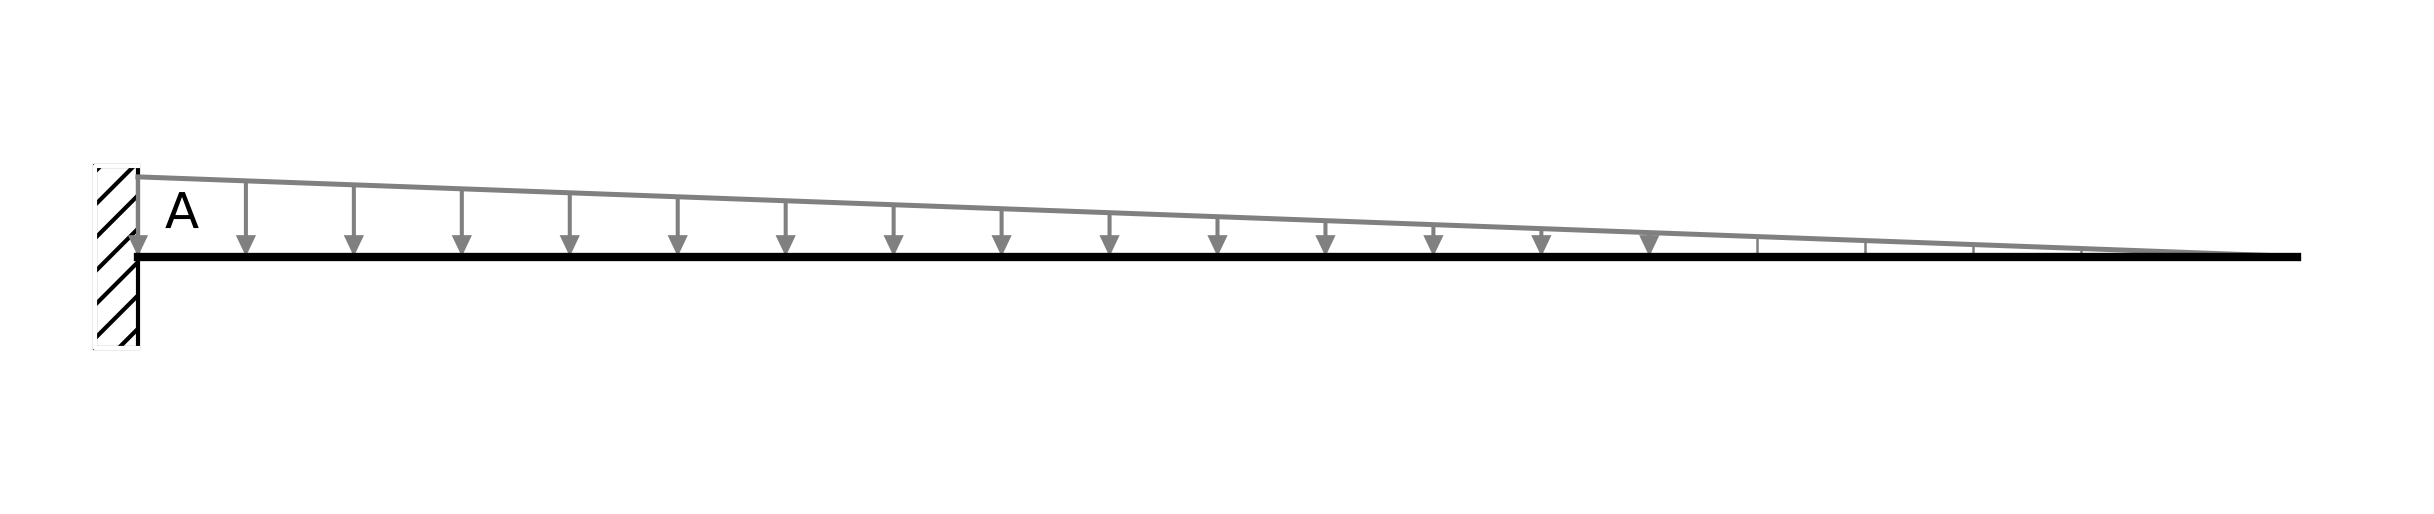

In [6]:
x_nodes = np.linspace(0, L, 91)   # every 0.1 m

beam = ps.EulerBeam2D(x_nodes, section=section)

# Built-in (fixed) support at the root: ux, uy and rotation all restrained.
beam.setFixity(0.0, ps.FixityTypes2D.getFixed(), label="A")

# Triangular load: -270 N/m at the root falling to 0 N/m at the tip. Negative = downward.
beam.addLinLoadVertical(0, L, [-q0, 0.0], label="q")

ps.plotBeamDiagram(beam)
plt.show()

In [7]:
analysis = ps.PyNiteAnalyzer2D(beam)
analysis.runAnalysis()

# Reactions live on the restrained node as [Fx, Fy, Mz], acting on the beam.
Fx_r, Fy_r, Mz_r = beam.nodes[0].rFrc
R_A_ps = Fy_r          # upward reaction                                   [N]
M_A_ps = -Mz_r         # internal moment at the wall, sagging positive     [N*m]

display(Markdown(
    f"**Reactions at A.** $R_A$ = {R_A_ps:,.1f} N upward. The wall applies a "
    f"{Mz_r:,.1f} N·m counter-clockwise couple, so the internal moment there is "
    f"$M_A$ = {M_A_ps:,.1f} N·m (hogging)."
))

**Reactions at A.** $R_A$ = 1,215.0 N upward. The wall applies a 3,645.0 N·m counter-clockwise couple, so the internal moment there is $M_A$ = -3,645.0 N·m (hogging).

### 2.1 Reading results at the nodes

`getSFD()` and `getBMD()` return arrays of length `2 * Nnodes`. Each node appears **twice**, holding the value just to its left and just to its right, so that jumps at point loads draw correctly. Element `0` is therefore the baseline in front of the support, **not** the shear at `x = 0`; taking `[1::2]` picks the right-hand value at each node.

PlaneSections also reports a hogging moment as **positive**, the opposite of Shigley's convention, so the helper below negates $M$. Its shear, deflection and rotation already follow Shigley's signs.

In [8]:
def node_results(beam):
    """Per-node x, V, M, y and theta as a DataFrame, in Shigley's sign convention.

    getSFD()/getBMD() double up every node (left value, right value) so that jumps at
    point loads plot correctly; [1::2] takes the right-hand value at each node.
    PlaneSections' moment is hogging-positive, so it is negated here.
    """
    xs, V = beam.getSFD()
    _,  M = beam.getBMD()
    uy, _ = ps.getVertDisp(beam)      # note: returns (disp, xcoords) in that order
    rot, _ = ps.getDisp(beam, 2)

    return pd.DataFrame({
        "x":     np.asarray(xs)[1::2],
        "V":     np.asarray(V)[1::2],
        "M":    -np.asarray(M)[1::2],
        "y":     np.asarray(uy),
        "theta": np.asarray(rot),
    })


r = node_results(beam)
exact = pd.DataFrame({"x": r["x"], "V": V_cf(r["x"]), "M": M_cf(r["x"]),
                      "y": y_cf(r["x"]), "theta": th_cf(r["x"])})

# Worst error over all 91 nodes, relative to the peak of each quantity
QTY = {"V": "shear V", "M": "moment M", "y": "deflection y", "theta": "slope θ"}
err_ps = {QTY[k]: (r[k] - exact[k]).abs().max() / exact[k].abs().max() for k in QTY}
display(Markdown("Worst error at any of the 91 nodes, relative to each quantity's peak: "
                 + ", ".join(f"{q} {e:.1e}" for q, e in err_ps.items()) + "."))

Worst error at any of the 91 nodes, relative to each quantity's peak: shear V 7.5e-10, moment M 1.5e-09, deflection y 2.0e-09, slope θ 2.2e-09.

### 2.2 Results at whole-metre stations

Whole metres land on nodes, so these are the solver's own values, not interpolations. The row at $x = 3$ m is Hibbeler's section $C$.

In [9]:
def station_table(fe, label):
    """Side-by-side table at whole-metre stations: FE value and closed form for each quantity."""
    at = fe[np.isclose(fe["x"] % 1.0, 0.0) | np.isclose(fe["x"] % 1.0, 1.0)].reset_index(drop=True)
    xs = at["x"].to_numpy()
    cols = {
        ("V [N]", label): at["V"], ("V [N]", "closed form"): V_cf(xs),
        ("M [N·m]", label): at["M"], ("M [N·m]", "closed form"): M_cf(xs),
        ("y [mm]", label): 1e3 * at["y"], ("y [mm]", "closed form"): 1e3 * y_cf(xs),
        ("θ [mrad]", label): 1e3 * at["theta"], ("θ [mrad]", "closed form"): 1e3 * th_cf(xs),
    }
    t = pd.DataFrame(cols, index=pd.Index(xs, name="x [m]"))
    return t.round({c: (1 if c[0][0] in "VM" else 5 if c[0][0] == "y" else 6) for c in t.columns}) + 0.0   # + 0.0 clears -0.0


station_table(r, "PlaneSections")

V [N]                   M [N·m]                    y [mm]  \
      PlaneSections closed form PlaneSections closed form PlaneSections   
x [m]                                                                     
0.0          1215.0      1215.0       -3645.0     -3645.0       0.00000   
1.0           960.0       960.0       -2560.0     -2560.0      -0.01812   
2.0           735.0       735.0       -1715.0     -1715.0      -0.06491   
3.0           540.0       540.0       -1080.0     -1080.0      -0.13095   
4.0           375.0       375.0        -625.0      -625.0      -0.20916   
5.0           240.0       240.0        -320.0      -320.0      -0.29444   
6.0           135.0       135.0        -135.0      -135.0      -0.38340   
7.0            60.0        60.0         -40.0       -40.0      -0.47394   
8.0            15.0        15.0          -5.0        -5.0      -0.56498   
9.0             0.0         0.0           0.0         0.0      -0.65610   

                       θ [mrad]              
      closed form PlaneSections closed form  
x [m]                                        
0.0       0.00000      0.000000    0.000000  
1.0      -0.01812     -0.034236   -0.034236  
2.0      -0.06491     -0.057778   -0.057778  
3.0      -0.13095     -0.073125   -0.073125  
4.0      -0.20916     -0.082444   -0.082444  
5.0      -0.29444     -0.087569   -0.087569  
6.0      -0.38340     -0.090000   -0.090000  
7.0      -0.47394     -0.090903   -0.090903  
8.0      -0.56498     -0.091111   -0.091111  
9.0      -0.65610     -0.091125   -0.091125

In [10]:
at_C = r[np.isclose(r["x"], x_C)].iloc[0]
display(Markdown(
    f"**At C** ($x$ = {x_C:g} m): $N_C$ = 0, $V_C$ = {at_C['V']:,.1f} N, "
    f"$M_C$ = {at_C['M']:,.1f} N·m. Hibbeler's answers to Ex. 1.1 are "
    f"540 N and −1080 N·m."
))

**At C** ($x$ = 3 m): $N_C$ = 0, $V_C$ = 540.0 N, $M_C$ = -1,080.0 N·m. Hibbeler's answers to Ex. 1.1 are 540 N and −1080 N·m.

## 3. Diagrams

One figure, four panels. The lines are the closed form from §1 and the circles are PlaneSections' nodal values, every 0.5 m so they don't hide the curve. The dotted line marks $C$.

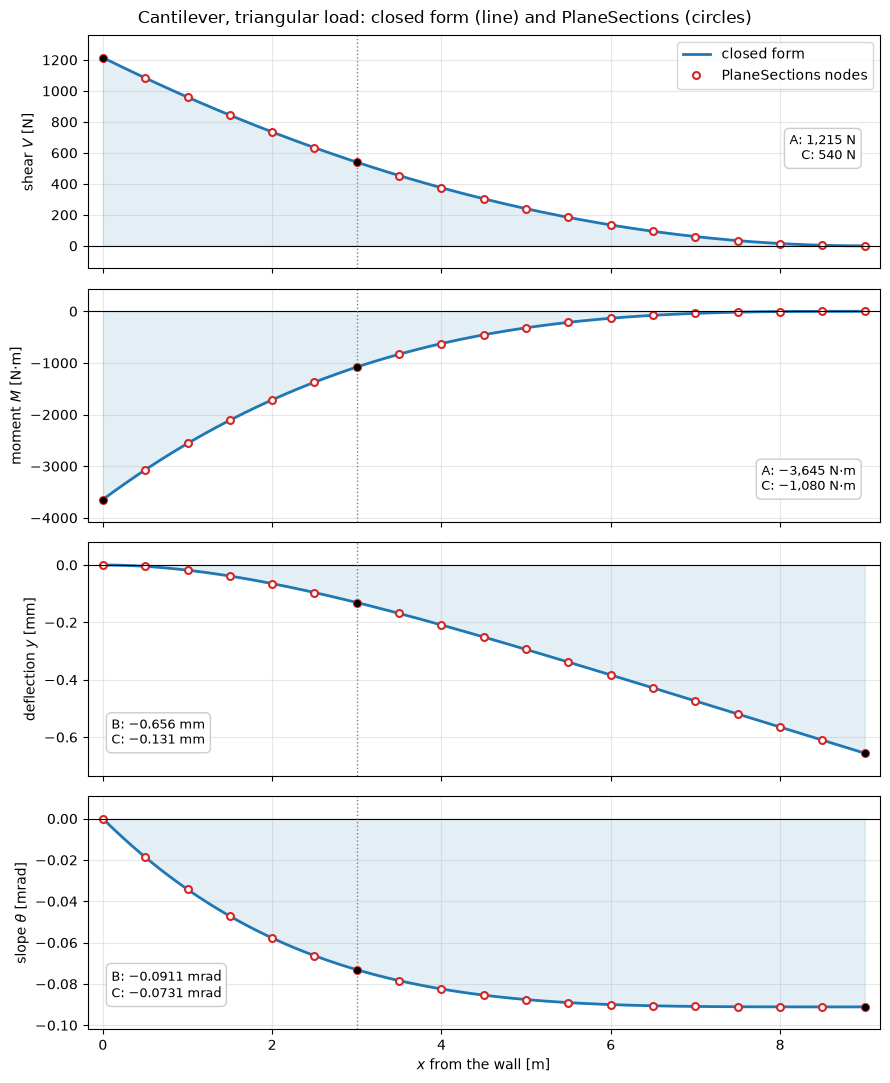

In [11]:
xf = np.linspace(0, L, 400)
sub = r.iloc[::5]
panels = [   # column, closed form, scale, axis label, number format, where the value box goes
    ("V", V_cf, 1.0, "shear $V$ [N]", "{:,.0f} N", (0.97, 0.45, "right")),
    ("M", M_cf, 1.0, "moment $M$ [N·m]", "{:,.0f} N·m", (0.97, 0.12, "right")),
    ("y", y_cf, 1e3, "deflection $y$ [mm]", "{:.3f} mm", (0.03, 0.12, "left")),
    ("theta", th_cf, 1e3, r"slope $\theta$ [mrad]", "{:.4f} mrad", (0.03, 0.12, "left")),
]

fig, axes = plt.subplots(4, 1, figsize=(9, 11), sharex=True)
for ax, (col, f, k, ylab, fmt, (bx, by, ha)) in zip(axes, panels):
    yf = k * f(xf)
    ax.plot(xf, yf, color="C0", lw=2, label="closed form")
    ax.fill_between(xf, yf, color="C0", alpha=0.12)
    ax.plot(sub["x"], k * sub[col], "o", ms=5, mfc="white", mec="C3", mew=1.5,
            label="PlaneSections nodes")
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(x_C, color="grey", ls=":", lw=1)
    ax.set_ylabel(ylab)
    ax.grid(alpha=0.3)
    ax.margins(x=0.02, y=0.12)
    # mark the governing value (root for V and M, tip for y and theta) and the value at C,
    # and list both in a box in an empty corner of the panel
    x_gov, name = (0.0, "A") if col in ("V", "M") else (L, "B")
    ax.plot([x_gov, x_C], [k * f(x_gov), k * f(x_C)], "o", color="black", ms=4, zorder=3)
    lines = [f"{p}: " + fmt.format(k * f(xp)).replace("-", "−") for p, xp in ((name, x_gov), ("C", x_C))]
    ax.text(bx, by, "\n".join(lines), transform=ax.transAxes, ha=ha, va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="0.8"))

axes[0].legend(loc="upper right")
fig.suptitle("Cantilever, triangular load: closed form (line) and PlaneSections (circles)")
axes[-1].set_xlabel("$x$ from the wall [m]")
plt.tight_layout()
plt.show()

## 4. Stress and the assumption ledger

The [design checklist](MECHANICAL-DESIGN-CHECKLIST__20260816-0939.md#02-the-assumption-ledger) asks for every modelling assumption to be written down and checked against the computed answer ([§9.6](MECHANICAL-DESIGN-CHECKLIST__20260816-0939.md#96-assumption-ledger-audit)). This beam's are below. The yield strength is that of AISI 1020 hot-rolled steel, $S_y = 210\ \text{MPa}$ (Shigley Table A-20, p. 1074), chosen as a low, common value. Carbon steel weighs $76.5\ \text{kN/m}^3$ (Shigley Table A-5, p. 1041).

In [12]:
sigma_max = abs(M_cf(0.0)) * (h / 2) / I    # Shigley Eq. 3-29a                     [Pa]
tau_max   = 1.5 * V_cf(0.0) / A             # Shigley Table 3-1, rectangle          [Pa]
y_B, th_B = y_cf(L), th_cf(L)               # tip deflection [m] and slope [rad]

S_y     = 210e6       # AISI 1020 HR, Shigley Table A-20                      [Pa]
gamma_s = 76.5e3      # unit weight of carbon steel, Shigley Table A-5        [N/m^3]
w_self  = gamma_s * A # self-weight of this section                           [N/m]

ledger = pd.DataFrame(
    [
        ("Euler–Bernoulli beam", "§4.2", "L/h ≳ 10", f"L/h = {L / h:.0f}", L / h >= 10),
        ("linear elastic", "§3.2", "σ_max < S_y",
         f"{sigma_max / 1e6:.3f} MPa = {sigma_max / S_y:.2%} of S_y", sigma_max < S_y),
        ("small deflection", "§3.2", "|y_B| < h/2",
         f"{abs(y_B) * 1e3:.3f} mm vs {h / 2 * 1e3:.0f} mm", abs(y_B) < h / 2),
        ("small rotation", "§3.2", "|θ_B| < 5°", f"{np.degrees(abs(th_B)):.4f}°",
         np.degrees(abs(th_B)) < 5),
        ("transverse shear negligible", "§4.2", "τ_max ≪ σ_max",
         f"{tau_max / 1e3:.1f} kPa vs {sigma_max / 1e6:.3f} MPa", tau_max < 0.1 * sigma_max),
        ("self-weight neglected", "—", "w_self ≪ q0",
         f"{w_self:,.0f} N/m = {w_self / q0:.0f} × q0", w_self < 0.05 * q0),
    ],
    columns=["assumption", "checklist", "criterion", "this beam", "holds"],
).set_index("assumption")
ledger["holds"] = ledger["holds"].map({True: "yes", False: "NO, see below"})
ledger

,checklist,criterion,this beam,holds
assumption,,,,
Euler–Bernoulli beam,§4.2,L/h ≳ 10,L/h = 30,yes
linear elastic,§3.2,σ_max < S_y,1.215 MPa = 0.58% of S_y,yes
small deflection,§3.2,|y_B| < h/2,0.656 mm vs 150 mm,yes
small rotation,§3.2,|θ_B| < 5°,0.0052°,yes
transverse shear negligible,§4.2,τ_max ≪ σ_max,30.4 kPa vs 1.215 MPa,yes
self-weight neglected,—,w_self ≪ q0,"4,590 N/m = 17 × q0","NO, see below"


**Self-weight is the one assumption that fails.** Hibbeler's problem gives no section, so it neglects self-weight. This notebook added a solid 300 × 200 mm steel section to make deflections concrete, and that bar weighs about 17 times the load it carries. The section is notional; treat it as a vehicle for the deflection numbers, not a design.

If it were real, its weight would be a uniform load $w$ to superpose. From Shigley Table A-9, beam 3 (p. 1048), $M_A = -wL^2/2$ and $y_B = -wL^4/8EI$; the next cell adds those to the triangular load.

In [13]:
M_A_self = -w_self * L**2 / 2             # Shigley Table A-9, beam 3   [N*m]
y_B_self = -w_self * L**4 / (8 * EI)       # Shigley Table A-9, beam 3   [m]

with_self = pd.DataFrame(
    {
        "triangular load only": [M_cf(0.0) / 1e3, y_B * 1e3, sigma_max / 1e6],
        "self-weight only": [M_A_self / 1e3, y_B_self * 1e3, abs(M_A_self) * h / 2 / I / 1e6],
    },
    index=["wall moment M_A [kN·m]", "tip deflection y_B [mm]", "peak bending stress [MPa]"],
)
with_self["both (superposed)"] = with_self.sum(axis=1)
with_self.round(3)

,triangular load only,self-weight only,both (superposed)
wall moment M_A [kN·m],-3.645,-185.895,-189.540
tip deflection y_B [mm],-0.656,-41.826,-42.482
peak bending stress [MPa],1.215,61.965,63.180


Even with its own weight the bar stays elastic (about 30% of $S_y$) and its tip deflection stays small against $h/2$, so the rest of the ledger holds. The applied load just becomes a small correction to the self-weight case.

## 5. Independent check: anaStruct

The checklist's [§9.1](MECHANICAL-DESIGN-CHECKLIST__20260816-0939.md#91-independent-check) asks for an independent check. Here it's a second FE package, [anaStruct](https://anastruct.readthedocs.io/), built from scratch rather than translated from the PlaneSections model. The beam has nine elements, one per metre, and each carries the linear load over its own length: anaStruct's `q_load` accepts `[q_start, q_end]`.

**anaStruct's signs differ from Shigley's.** It reports reactions opposite to the load that causes them, node deflection $u_y$ positive downward, and both $V$ and $M$ opposite to Shigley's convention. The cell flips each one, and the comparison with the closed form is then signed, not just magnitudes. Its node values are exact; between nodes its deflection curve is a numerical integral, so only nodes are compared.

In [14]:
ss = SystemElements(EA=E * A, EI=EI)
edges = np.arange(0.0, L + 1e-9, 1.0)
for i, (x1, x2) in enumerate(zip(edges[:-1], edges[1:]), start=1):
    ss.add_element(location=[[x1, 0], [x2, 0]])
    ss.q_load(q=[-q0 * (1 - x1 / L), -q0 * (1 - x2 / L)], element_id=i, direction="y")
ss.add_support_fixed(node_id=1)
ss.solve()

n_el = len(edges) - 1
node = [ss.get_node_results_system(node_id=k) for k in range(1, n_el + 2)]
elem = [ss.get_element_results(element_id=e, verbose=True) for e in range(1, n_el + 1)]

R_A_ana = -node[0]["Fy"]            # reactions come back opposite in sign
M_A_ana = node[0]["Tz"]             # internal wall moment = -(reaction couple) = Tz

# V and M at each node: start of each element, plus the end of the last one; flip both
V_ana = -np.r_[[e["Q"][0] for e in elem], elem[-1]["Q"][-1]]
M_ana = -np.r_[[e["M"][0] for e in elem], elem[-1]["M"][-1]]

ana = pd.DataFrame({
    "x": edges,
    "V": V_ana,
    "M": M_ana,
    "y": [-n["uy"] for n in node],       # node uy is positive down
    "theta": [-n["phi_z"] for n in node],
})

exact_ana = {"V": V_cf(edges), "M": M_cf(edges), "y": y_cf(edges), "theta": th_cf(edges)}
err_ana = {QTY[k]: np.abs(ana[k] - exact_ana[k]).max() / np.abs(exact_ana[k]).max() for k in QTY}

display(Markdown(f"**anaStruct reactions.** $R_A$ = {R_A_ana:,.1f} N, $M_A$ = {M_A_ana:,.1f} N·m."))
station_table(ana, "anaStruct")

**anaStruct reactions.** $R_A$ = 1,215.0 N, $M_A$ = -3,645.0 N·m.

V [N]               M [N·m]                y [mm]              \
      anaStruct closed form anaStruct closed form anaStruct closed form   
x [m]                                                                     
0.0      1215.0      1215.0   -3645.0     -3645.0   0.00000     0.00000   
1.0       960.0       960.0   -2560.0     -2560.0  -0.01812    -0.01812   
2.0       735.0       735.0   -1715.0     -1715.0  -0.06491    -0.06491   
3.0       540.0       540.0   -1080.0     -1080.0  -0.13095    -0.13095   
4.0       375.0       375.0    -625.0      -625.0  -0.20916    -0.20916   
5.0       240.0       240.0    -320.0      -320.0  -0.29444    -0.29444   
6.0       135.0       135.0    -135.0      -135.0  -0.38340    -0.38340   
7.0        60.0        60.0     -40.0       -40.0  -0.47394    -0.47394   
8.0        15.0        15.0      -5.0        -5.0  -0.56498    -0.56498   
9.0         0.0         0.0       0.0         0.0  -0.65610    -0.65610   

       θ [mrad]              
      anaStruct closed form  
x [m]                        
0.0    0.000000    0.000000  
1.0   -0.034236   -0.034236  
2.0   -0.057778   -0.057778  
3.0   -0.073125   -0.073125  
4.0   -0.082444   -0.082444  
5.0   -0.087569   -0.087569  
6.0   -0.090000   -0.090000  
7.0   -0.090903   -0.090903  
8.0   -0.091111   -0.091111  
9.0   -0.091125   -0.091125

In [15]:
pd.DataFrame({"PlaneSections (91 nodes)": err_ps, "anaStruct (10 nodes)": err_ana}) \
    .rename_axis("max |FE − closed form| / peak").map("{:.1e}".format)

,PlaneSections (91 nodes),anaStruct (10 nodes)
max |FE − closed form| / peak,,
shear V,7.5e-10,1.3e-13
moment M,1.5e-09,2.2e-13
deflection y,2.0e-09,5.1e-09
slope θ,2.2e-09,6.2e-09


## 6. What if you only had a constant distributed load?

`addLinLoadVertical` is new-ish. Plenty of tools, and the older PlaneSections API, only offer a **constant** $q$ over a span, so the taper has to be approximated by $N$ strips, each carrying the load intensity at its own midpoint.

Sampling at the midpoint makes each strip's resultant exactly right, so the **total load is exact for any $N$** and the root shear comes out at 1215 N every time. What the staircase gets wrong is *where* the load sits, so the error shows up in the **moment**.

In [16]:
def strip_model(n_strips):
    """Triangular load approximated by n constant-q strips, sampled at strip midpoints."""
    edges = np.linspace(0, L, n_strips + 1)
    # make sure every strip boundary is also a node
    nodes = np.unique(np.concatenate([np.linspace(0, L, 91), edges]))

    b_ = ps.EulerBeam2D(nodes, section=section)
    b_.setFixity(0.0, ps.FixityTypes2D.getFixed())
    for x1, x2 in zip(edges[:-1], edges[1:]):
        q_mid = -q0 * (1.0 - 0.5 * (x1 + x2) / L)
        b_.addDistLoadVertical(x1, x2, q_mid)

    ps.PyNiteAnalyzer2D(b_).runAnalysis()
    return node_results(b_)


V_ex, M_ex = V_cf(0.0), M_cf(0.0)
counts = [3, 6, 9, 18, 36, 72]

rows = []
for n in counts:
    rn = strip_model(n)
    rows.append((n, rn["V"][0], 100 * (rn["V"][0] - V_ex) / V_ex,
                 rn["M"][0], 100 * (rn["M"][0] - M_ex) / M_ex))
rows.append(("linear load", r["V"][0], 100 * (r["V"][0] - V_ex) / V_ex,
             r["M"][0], 100 * (r["M"][0] - M_ex) / M_ex))
rows.append(("closed form", V_ex, 0.0, M_ex, 0.0))

strips = pd.DataFrame(rows, columns=["strips N", "V(0) [N]", "V error [%]", "M(0) [N·m]", "M error [%]"]) \
    .set_index("strips N")
strips.round({"V(0) [N]": 3, "M(0) [N·m]": 3, "V error [%]": 4, "M error [%]": 4}) + 0.0

,V(0) [N],V error [%],M(0) [N·m],M error [%]
strips N,,,,
3,1215.0,0.0,-3847.500,5.5556
6,1215.0,0.0,-3695.625,1.3889
9,1215.0,0.0,-3667.500,0.6173
18,1215.0,0.0,-3650.625,0.1543
36,1215.0,0.0,-3646.406,0.0386
72,1215.0,0.0,-3645.351,0.0096
linear load,1215.0,0.0,-3645.000,0.0000
closed form,1215.0,0.0,-3645.000,0.0000


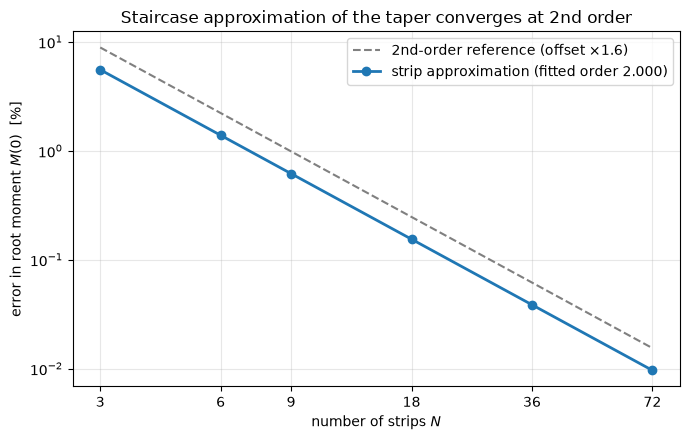

Doubling the strip count quarters the error (fitted order 2.000). Even 72 strips leave the root moment 0.0096% off, while `addLinLoadVertical` is exact with a single load object.

In [17]:
errs = strips.loc[counts, "M error [%]"].abs().to_numpy(dtype=float)
order = -np.polyfit(np.log(counts), np.log(errs), 1)[0]     # slope on log-log axes

fig, ax = plt.subplots(figsize=(7, 4.5))
# Second-order reference slope, offset a little so it does not hide under the data
# (the two lie on top of each other almost exactly, which is the point).
ref = errs[0] * (np.array(counts, dtype=float) / counts[0]) ** -2.0
ax.loglog(counts, ref * 1.6, "--", color="grey", lw=1.5, label="2nd-order reference (offset ×1.6)")
ax.loglog(counts, errs, "o-", lw=2, label=f"strip approximation (fitted order {order:.3f})")

ax.set_xlabel("number of strips $N$")
ax.set_ylabel("error in root moment $M(0)$  [%]")
ax.set_title("Staircase approximation of the taper converges at 2nd order")
ax.set_xticks(counts)
ax.set_xticklabels([str(c) for c in counts])
ax.minorticks_off()
ax.grid(True, which="major", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

display(Markdown(
    f"Doubling the strip count quarters the error (fitted order {order:.3f}). Even {counts[-1]} "
    f"strips leave the root moment {errs[-1]:.4f}% off, while `addLinLoadVertical` is exact "
    "with a single load object."
))

## 7. Checks

Every number above against its reference. Textbook answers come first, then the closed form, then agreement between methods. A check passes when the two values agree to `rel_tol`, or, for an error measure, when it is below the bound.

In [18]:
TOL = 1e-6
checks = []


def check(name, got, ref, source, rel_tol=TOL):
    checks.append((name, f"{got:.6g}", f"{ref:.6g}", source, math.isclose(got, ref, rel_tol=rel_tol)))


def bound(name, err, limit, source):
    checks.append((name, f"{err:.2e}", f"≤ {limit:.0e}", source, err <= limit))


# Textbook answers
check("R_A, PlaneSections [N]", R_A_ps, 1215.0, "Hibbeler Fig. 1–4c")
check("M_A, PlaneSections [N·m]", M_A_ps, -3645.0, "Hibbeler Fig. 1–4c")
check("V_C, PlaneSections [N]", at_C["V"], 540.0, "Hibbeler Ex. 1.1")
check("M_C, PlaneSections [N·m]", at_C["M"], -1080.0, "Hibbeler Ex. 1.1")
check("V_C, hand calc [N]", hc_V_C.to(N).magnitude, 540.0, "Hibbeler Ex. 1.1")
check("M_C, hand calc [N·m]", hc_M_C.to(N * m).magnitude, -1080.0, "Hibbeler Ex. 1.1")

# Closed form (Hibbeler App. C for y_B and theta_B)
y_B_cf, th_B_cf = -q0 * L**4 / (30 * EI), -q0 * L**3 / (24 * EI)
check("y_B, PlaneSections [m]", r["y"].iloc[-1], y_B_cf, "Hibbeler App. C")
check("θ_B, PlaneSections [rad]", r["theta"].iloc[-1], th_B_cf, "Hibbeler App. C")
check("y_B, hand calc [m]", hc_y_B.to(m).magnitude, y_B_cf, "Hibbeler App. C")
check("θ_B, hand calc [rad]", hc_th_B.to("rad").magnitude, th_B_cf, "Hibbeler App. C")
check("σ_max, hand calc [Pa]", hc_sigma.to("Pa").magnitude, sigma_max, "Shigley Eq. 3-29a")
check("τ_max, hand calc [Pa]", hc_tau.to("Pa").magnitude, tau_max, "Shigley Table 3-1")
for k, ok in sym_ok.items():
    checks.append((f"SymPy: {k}", "simplifies", "to 0", "§1.1–1.2", bool(ok)))

# Every node against the closed form
for q, e in err_ps.items():
    bound(f"PlaneSections, all nodes: {q}", e, TOL, "closed form, §1")

# Second package
check("R_A, anaStruct [N]", R_A_ana, R_A_ps, "PlaneSections")
check("M_A, anaStruct [N·m]", M_A_ana, M_A_ps, "PlaneSections")
for q, e in err_ana.items():
    bound(f"anaStruct, all nodes: {q}", e, TOL, "closed form, §1")

# Strip study
bound("strips: V(0) exact for every N", strips.loc[counts, "V error [%]"].abs().max() / 100, TOL, "W = q0 L/2")
check("strips: convergence order", order, 2.0, "midpoint rule, O(N⁻²)", rel_tol=0.02)

table = pd.DataFrame(checks, columns=["check", "computed", "reference", "source", "pass"])
table["pass"] = table["pass"].map({True: "PASS", False: "FAIL"})
table.index = range(1, len(table) + 1)
display(table)

n_fail = (table["pass"] == "FAIL").sum()
display(Markdown(f"**{len(table) - n_fail} of {len(table)} checks pass.**"))
if n_fail:
    raise AssertionError(f"{n_fail} check(s) failed; see the table above")

,check,computed,reference,source,pass
1,"R_A, PlaneSections [N]",1215,1215,Hibbeler Fig. 1–4c,PASS
2,"M_A, PlaneSections [N·m]",-3645,-3645,Hibbeler Fig. 1–4c,PASS
3,"V_C, PlaneSections [N]",540,540,Hibbeler Ex. 1.1,PASS
4,"M_C, PlaneSections [N·m]",-1080,-1080,Hibbeler Ex. 1.1,PASS
5,"V_C, hand calc [N]",540,540,Hibbeler Ex. 1.1,PASS
6,"M_C, hand calc [N·m]",-1080,-1080,Hibbeler Ex. 1.1,PASS
7,"y_B, PlaneSections [m]",-0.0006561,-0.0006561,Hibbeler App. C,PASS
8,"θ_B, PlaneSections [rad]",-9.1125e-05,-9.1125e-05,Hibbeler App. C,PASS
9,"y_B, hand calc [m]",-0.0006561,-0.0006561,Hibbeler App. C,PASS
10,"θ_B, hand calc [rad]",-9.1125e-05,-9.1125e-05,Hibbeler App. C,PASS


**29 of 29 checks pass.**

## 8. Summary

| Quantity | Formula | Value | Source |
|---|---|---|---|
| Resultant load $W$ | $q_0 L/2$ | **1215 N** at 3.0 m from the wall | statics |
| Wall reaction $R_A$ | $q_0 L/2$ | **1215 N** upward | Hibbeler Fig. 1–4c |
| Wall moment $M_A$ | $-q_0 L^2/6$ | **−3645 N·m** (hogging) | Hibbeler Fig. 1–4c |
| Shear at $C$, $V_C$ | $q_0 L s^2/2$ | **540 N** | Hibbeler Ex. 1.1 |
| Moment at $C$, $M_C$ | $-q_0 L^2 s^3/6$ | **−1080 N·m** | Hibbeler Ex. 1.1 |
| Tip deflection $y_B$ | $-q_0 L^4/30EI$ | **−0.656 mm** ($-59049/EI$ m) | Hibbeler App. C |
| Tip slope $\theta_B$ | $-q_0 L^3/24EI$ | **−0.0911 mrad** ($-8201.25/EI$ rad) | Hibbeler App. C |
| Peak bending stress | $\lvert M_A\rvert c/I$ | **1.215 MPa** at the wall | Shigley Eq. 3-29a |
| Peak shear stress | $3R_A/2A$ | **30.4 kPa** at the wall | Shigley Table 3-1 |

The deflection, slope and stress rows use the notebook's 300 × 200 mm steel section ($EI = 90\ \text{MN}\cdot\text{m}^2$). PlaneSections, anaStruct, SymPy and the hand calculation all agree with the closed form to better than $10^{-6}$ relative. The section's own weight, neglected as in the textbook, would be 17 times the applied load (§4).

## API notes

**planesections 1.4.2**

| older API | 1.4.2 |
|---|---|
| `ps.OpenSeesAnalyzer2D(beam)` | **`ps.PyNiteAnalyzer2D(beam)`**: the backend moved from OpenSeesPy to PyNiteFEA |
| constant `q` only | **`addLinLoadVertical(x1, x2, [q1, q2])`** for tapered loads |

* **`ps.SectionBasic2D` is broken in 1.4.2.** Constructing it raises
  `AttributeError: 'super' object has no attribute '__post_init__'`. That is the natural
  way to set `E` and `Iz` directly (for example to normalise `EI = 1`), so until it is fixed use
  `ps.SectionRectangle` and work with a real section, as done here.
* **`getSFD()` / `getBMD()` return `2 * Nnodes` values**, each node duplicated
  (left value, right value) so jumps plot correctly. Index 0 is the baseline, not the
  value at `x = 0`. Use `[1::2]`.
* **`getBMD()` is hogging-positive**, opposite to Shigley and Hibbeler. Negate it, and pass
  `scale=-1` to `ps.plotMoment` to draw the moment diagram the textbook way up.
* **`ps.getVertDisp(beam)` returns `(disp, xcoords)`** in that order, displacement
  first. Unpacking it the other way round silently hands you the x coordinates.
* Reactions are on the node: `beam.nodes[i].rFrc` gives `[Fx, Fy, Mz]`, acting on the beam.

**anaStruct 1.7.0**

* `get_node_results_system()` reports reactions **opposite** in sign to the loads that cause them,
  and node `uy` **positive downward**.
* For elements drawn left to right, its shear `Q` and moment `M` are **both opposite** to
  Shigley's convention. Flip them, then check the reactions against statics.

**handcalcs 1.11.0**

* Set `preferred_string_formatter` to `"~L"`, or pint's unit names print in full (`newton`, `millimeter`).
* The `@handcalc` decorator keeps the record's variables inside a function, so names like `L` and
  `M_A` don't overwrite the notebook's floats.
* Keep `_` and `^` out of comments in rendered code. handcalcs wraps comments in `\textrm{}`, and
  KaTeX (VS Code) fails the whole cell on an underscore.